In [3]:
%pip install pandas pyarrow zstandard

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
print("Notebook folder:", os.getcwd())
print([f for f in os.listdir() if f.endswith(".zst")])
print(os.listdir("DATA"))

Notebook folder: C:\Users\thiya\Desktop\DATAANALYTICS
[]
['.ipynb_checkpoints', 'ais-2025-10-01.csv', 'ais-2025-10-02.csv', 'ais-2025-10-03.csv', 'ais-2025-10-04.csv', 'ais-2025-10-05.csv', 'ais-2025-10-06.csv', 'ais-2025-10-07.csv', 'ais-2025-10-08.csv', 'ais-2025-10-09.csv', 'ais-2025-10-10.csv', 'ais-2025-10-11.csv', 'ais-2025-10-12.csv', 'ais-2025-10-13.csv', 'ais-2025-10-14.csv', 'portwatch.csv', 'weather.csv']


In [5]:
import pandas as pd

f = "DATA/ais-2025-10-01.csv"

cols = ["mmsi","base_date_time","latitude","longitude","sog","cog",
        "heading","vessel_type","status","length","width","draft"]

parts = []
total = 0
for chunk in pd.read_csv(f, usecols=cols, chunksize=500_000):
    total += len(chunk)
    keep = chunk[chunk.latitude.between(33.40, 33.85) &
                 chunk.longitude.between(-118.60, -117.90) &
                 chunk.vessel_type.between(70, 89)]
    parts.append(keep)

df = pd.concat(parts)
print("Rows in whole file:", total)
print("Rows near LA/Long Beach (cargo + tanker):", len(df))
print("Different ships:", df.mmsi.nunique())
df.head()

Rows in whole file: 8667385
Rows near LA/Long Beach (cargo + tanker): 15322
Different ships: 53


,mmsi,base_date_time,longitude,latitude,sog,cog,heading,vessel_type,status,length,width,draft
1322,477117900,2025-10-01 00:00:11,-118.19285,33.73677,0.2,87.9,91.0,71.0,0.0,335.0,48.0,10.8
2400,477117900,2025-10-01 00:00:00,-118.19285,33.73677,0.2,90.1,91.0,71.0,0.0,335.0,48.0,10.8
3759,366855000,2025-10-01 00:00:06,-118.27120,33.74943,4.4,208.1,207.0,80.0,0.0,183.0,32.0,9.7
4276,538009707,2025-10-01 00:00:22,-118.25720,33.75997,0.0,115.7,68.0,72.0,5.0,210.0,30.0,10.5
4392,368237190,2025-10-01 00:00:09,-118.22473,33.74602,0.0,107.0,NaN,70.0,0.0,55.0,15.0,3.3


status
5.0    8606
0.0    3499
1.0    2770
Name: count, dtype: int64


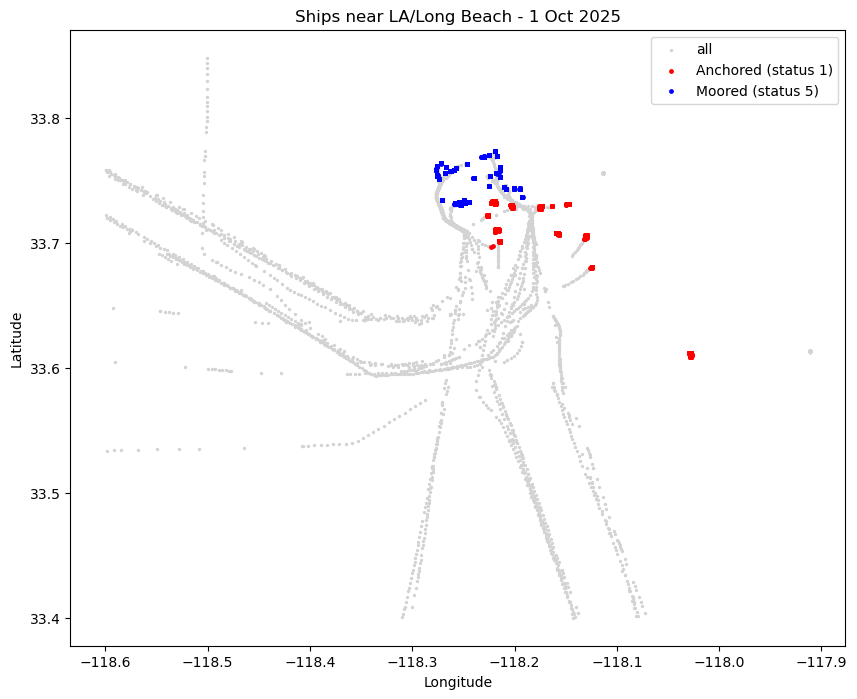

In [6]:
import matplotlib.pyplot as plt

print(df.status.value_counts())  

plt.figure(figsize=(10,8))
plt.scatter(df.longitude, df.latitude, s=2, c="lightgray", label="all")
a = df[df.status == 1]
m = df[df.status == 5]
plt.scatter(a.longitude, a.latitude, s=6, c="red", label="Anchored (status 1)")
plt.scatter(m.longitude, m.latitude, s=6, c="blue", label="Moored (status 5)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.legend(); plt.title("Ships near LA/Long Beach - 1 Oct 2025")
plt.show()

In [7]:
print("ANCHORED (status 1):")
print(df[df.status == 1][["longitude","latitude"]].describe().round(4))

print("\nMOORED (status 5):")
print(df[df.status == 5][["longitude","latitude"]].describe().round(4))

# which ships are anchored, and how many points each
print("\nAnchored ships:")
print(df[df.status == 1].groupby("mmsi").agg(
    points=("mmsi","size"),
    lon=("longitude","mean"),
    lat=("latitude","mean")).round(4))

ANCHORED (status 1):
       longitude   latitude
count  2770.0000  2770.0000
mean   -118.1587    33.7009
std       0.0647     0.0406
min    -118.2272    33.6091
25%    -118.2150    33.7056
50%    -118.1633    33.7099
75%    -118.1299    33.7295
max    -118.0270    33.7337

MOORED (status 5):
       longitude   latitude
count  8606.0000  8606.0000
mean   -118.2414    33.7480
std       0.0251     0.0127
min    -118.2770    33.7307
25%    -118.2593    33.7344
50%    -118.2487    33.7521
75%    -118.2181    33.7586
max    -118.1922    33.7735

Anchored ships:
           points       lon      lat
mmsi                                
235076274     424 -118.1577  33.7075
249982000     168 -118.2146  33.7013
352003368     175 -118.1475  33.7313
372712000     226 -118.2171  33.7107
538003274     275 -118.2200  33.7328
538005177     169 -118.2262  33.7221
538009205     377 -118.2003  33.7296
538010103     434 -118.0277  33.6108
563087300     182 -118.1745  33.7284
566776000      51 -118.1242  33

zone
berth        10684
other         2461
anchorage     2177
Name: count, dtype: int64


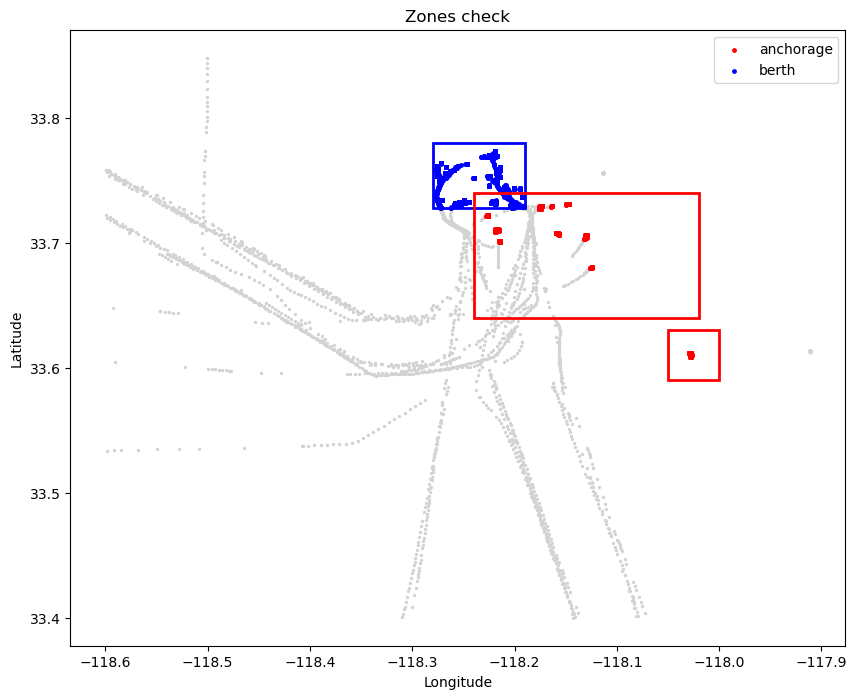

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
BERTH   = (-118.280, -118.190, 33.728, 33.780)
ANCH_IN = (-118.240, -118.020, 33.640, 33.740)   # main anchorage
ANCH_OUT= (-118.050, -118.000, 33.590, 33.630)   # far outer anchorage
def inside(d, z):
    return d.longitude.between(z[0], z[1]) & d.latitude.between(z[2], z[3])
def assign_zone(d):
    zone = pd.Series("other", index=d.index)
    in_anch = (inside(d, ANCH_IN) | inside(d, ANCH_OUT)) & (d.sog < 1.0)
    zone[in_anch] = "anchorage"
    zone[inside(d, BERTH)] = "berth"       # berth has priority
    return zone
df["zone"] = assign_zone(df)
print(df.zone.value_counts())
fig, ax = plt.subplots(figsize=(10,8))
ax.scatter(df.longitude, df.latitude, s=2, c="lightgray")
colors = {"anchorage":"red", "berth":"blue"}
for z, c in colors.items():
    s = df[df.zone == z]
    ax.scatter(s.longitude, s.latitude, s=6, c=c, label=z)
for box, c in [(BERTH,"blue"),(ANCH_IN,"red"),(ANCH_OUT,"red")]:
    ax.add_patch(Rectangle((box[0], box[2]), box[1]-box[0], box[3]-box[2],
                           fill=False, edgecolor=c, linewidth=2))
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(); ax.set_title("Zones check")
plt.show()

In [9]:

def assign_zone(d):
    zone = pd.Series("other", index=d.index)
    in_anch = (inside(d, ANCH_IN) | inside(d, ANCH_OUT)) & (d.sog < 1.0)
    zone[in_anch] = "anchorage"
    zone[inside(d, BERTH) & (d.sog < 1.0)] = "berth"
    return zone
d = df.copy()
d["base_date_time"] = pd.to_datetime(d["base_date_time"])
d["zone"] = assign_zone(d)
d = d.sort_values(["mmsi", "base_date_time"])
print(d.zone.value_counts())
rows, no_berth = [], []
for mmsi, g in d.groupby("mmsi"):
    start = None
    for t, z in zip(g.base_date_time, g.zone):
        if z == "anchorage" and start is None:
            start = t
        elif z == "berth" and start is not None:
            rows.append((mmsi, start, t, (t - start).total_seconds() / 3600))
            start = None
    if start is not None:
        no_berth.append(mmsi)     
waits = pd.DataFrame(rows, columns=["mmsi", "anchorage_arrival", "berth_entry", "wait_hours"])
print("\nCompleted visits:", len(waits))
print("Ships anchored but no berth entry yet:", len(no_berth))
waits

zone
berth        10325
other         2820
anchorage     2177
Name: count, dtype: int64

Completed visits: 4
Ships anchored but no berth entry yet: 6


,mmsi,anchorage_arrival,berth_entry,wait_hours
0,249982000,2025-10-01 00:00:15,2025-10-01 13:01:38,13.023056
1,538005177,2025-10-01 00:01:41,2025-10-01 10:13:48,10.201944
2,538009205,2025-10-01 00:01:29,2025-10-01 01:44:01,1.708889
3,566776000,2025-10-01 00:01:00,2025-10-01 08:01:15,8.004167


In [10]:
import pandas as pd, glob
cols = ["mmsi","base_date_time","latitude","longitude","sog","cog",
        "heading","vessel_type","status","length","width","draft"]

files = sorted(glob.glob("DATA/ais-2025-10-*.csv*"))
print("Files found:", len(files))
parts = []
for f in files:
    n_before, n_after = 0, 0
    for chunk in pd.read_csv(f, usecols=cols, chunksize=500_000):
        n_before += len(chunk)
        keep = chunk[chunk.latitude.between(33.40, 33.85) &
                     chunk.longitude.between(-118.60, -117.90) &
                     chunk.vessel_type.between(70, 89)]
        n_after += len(keep)
        parts.append(keep)
    print(f, "| all rows:", n_before, "| kept:", n_after)

df = pd.concat(parts)
df["base_date_time"] = pd.to_datetime(df["base_date_time"])
n1 = len(df)
df = df.drop_duplicates().sort_values(["mmsi","base_date_time"]).reset_index(drop=True)
print("\nBefore duplicate removal:", n1, "| After:", len(df))
print("Ships:", df.mmsi.nunique())
print("From", df.base_date_time.min(), "to", df.base_date_time.max())

df.to_parquet("ais_lalb_filtered.parquet")

Files found: 14
DATA\ais-2025-10-01.csv | all rows: 8667385 | kept: 15322
DATA\ais-2025-10-02.csv | all rows: 8449595 | kept: 12162
DATA\ais-2025-10-03.csv | all rows: 8161609 | kept: 13211
DATA\ais-2025-10-04.csv | all rows: 8263908 | kept: 14443
DATA\ais-2025-10-05.csv | all rows: 8386507 | kept: 12607
DATA\ais-2025-10-06.csv | all rows: 8376283 | kept: 13660
DATA\ais-2025-10-07.csv | all rows: 8431777 | kept: 14743
DATA\ais-2025-10-08.csv | all rows: 8416054 | kept: 13645
DATA\ais-2025-10-09.csv | all rows: 8456618 | kept: 13661
DATA\ais-2025-10-10.csv | all rows: 7540746 | kept: 11728
DATA\ais-2025-10-11.csv | all rows: 8083415 | kept: 12032
DATA\ais-2025-10-12.csv | all rows: 8539073 | kept: 13392
DATA\ais-2025-10-13.csv | all rows: 3351025 | kept: 7164
DATA\ais-2025-10-14.csv | all rows: 8069140 | kept: 18790

Before duplicate removal: 186560 | After: 183736
Ships: 191
From 2025-10-01 00:00:00 to 2025-10-14 23:59:56


In [11]:
import pandas as pd

df = pd.read_parquet("ais_lalb_filtered.parquet")
df = df.sort_values(["mmsi","base_date_time"]).reset_index(drop=True)

# Zones (same boxes as before)
BERTH   = (-118.280, -118.190, 33.728, 33.780)
ANCH_IN = (-118.240, -118.020, 33.640, 33.740)
ANCH_OUT= (-118.050, -118.000, 33.590, 33.630)

def inside(d, z):
    return d.longitude.between(z[0], z[1]) & d.latitude.between(z[2], z[3])

zone = pd.Series("other", index=df.index)
zone[(inside(df, ANCH_IN) | inside(df, ANCH_OUT)) & (df.sog < 1.0)] = "anchorage"
zone[inside(df, BERTH) & (df.sog < 1.0)] = "berth"
df["zone"] = zone

data_start = df.base_date_time.min()
data_end   = df.base_date_time.max()
MAX_GAP_H  = 6          # drop visits with a signal gap longer than this
EDGE_H     = 2          # ignore anchorage starts in the first 2 hours of data

rows = []
for mmsi, g in df.groupby("mmsi"):
    times = g.base_date_time.values
    zones = g.zone.values
    start, last_t, bad_gap = None, None, False
    for t, z in zip(pd.to_datetime(times), zones):
        if last_t is not None and start is not None:
            if (t - last_t).total_seconds()/3600 > MAX_GAP_H:
                bad_gap = True
        if z == "anchorage" and start is None:
            start, bad_gap = t, False
        elif z == "berth" and start is not None:
            rows.append((mmsi, start, t, (t-start).total_seconds()/3600, "complete", bad_gap))
            start, bad_gap = None, False
        last_t = t
    if start is not None:
        rows.append((mmsi, start, pd.NaT, None, "still_waiting_at_end", bad_gap))

v = pd.DataFrame(rows, columns=["mmsi","anchorage_arrival","berth_entry","wait_hours","status","has_gap"])
v["starts_at_edge"] = v.anchorage_arrival < data_start + pd.Timedelta(hours=EDGE_H)

print("All detected visits:", len(v))
print(v.status.value_counts())
print("Dropped - start at data edge:", int(v.starts_at_edge.sum()))
print("Dropped - signal gap > 6h:", int(v.has_gap.sum()))

good = v[(v.status=="complete") & (~v.starts_at_edge) & (~v.has_gap)].copy()
print("\nUSABLE visits:", len(good))
print(good.wait_hours.describe().round(2))

good.to_csv("waiting_times.csv", index=False)

# Coverage check: ships and rows per day
chk = df.groupby(df.base_date_time.dt.date).agg(rows=("mmsi","size"), ships=("mmsi","nunique"))
print("\n", chk)

All detected visits: 67
status
still_waiting_at_end    34
complete                33
Name: count, dtype: int64
Dropped - start at data edge: 7
Dropped - signal gap > 6h: 14

USABLE visits: 22
count     22.00
mean      19.06
std       27.16
min        0.04
25%        3.16
50%       10.29
75%       22.14
max      109.87
Name: wait_hours, dtype: float64

                  rows  ships
base_date_time              
2025-10-01      15186     53
2025-10-02      11919     53
2025-10-03      13117     50
2025-10-04      14272     53
2025-10-05      12353     47
2025-10-06      13486     50
2025-10-07      14625     52
2025-10-08      13517     49
2025-10-09      13463     47
2025-10-10      11298     47
2025-10-11      11640     52
2025-10-12      13094     53
2025-10-13       7040     49
2025-10-14      18726     56


In [12]:
sw = v[v.status == "still_waiting_at_end"]
out = []
for mmsi, arr in zip(sw.mmsi, sw.anchorage_arrival):
    g = df[(df.mmsi == mmsi) & (df.base_date_time >= arr)]
    last = g.iloc[-1]
    out.append((mmsi, arr, last.base_date_time, last.zone,
                round(last.latitude, 3), round(last.longitude, 3)))
d = pd.DataFrame(out, columns=["mmsi","arrived","last_seen","last_zone","lat","lon"])
d["last_seen_near_data_end"] = d.last_seen > data_end - pd.Timedelta(hours=6)
print(d.to_string())
print(d.last_seen_near_data_end.value_counts())
print(d.last_zone.value_counts())

         mmsi             arrived           last_seen  last_zone     lat      lon  last_seen_near_data_end
0   205184000 2025-10-10 03:55:21 2025-10-14 23:57:59  anchorage  33.688 -118.148                     True
1   219413000 2025-10-02 07:31:31 2025-10-03 02:21:31      other  33.661 -118.599                    False
2   229957000 2025-10-06 04:13:58 2025-10-14 23:57:54      other  33.668 -118.184                     True
3   235084298 2025-10-02 13:49:10 2025-10-03 04:44:14      other  33.756 -118.585                    False
4   235108525 2025-10-07 15:00:04 2025-10-11 00:29:54      other  33.759 -118.599                    False
5   241440000 2025-10-11 18:33:12 2025-10-14 23:26:52      other  33.578 -118.274                     True
6   241520000 2025-10-07 08:45:11 2025-10-08 21:03:41      other  33.403 -118.143                    False
7   248672000 2025-10-08 11:57:25 2025-10-14 23:58:56      other  33.675 -118.120                     True
8   256062000 2025-10-05 14:02:47 202

In [15]:
import pandas as pd, numpy as np

# 1) Load the saved data
df = pd.read_parquet("ais_lalb_filtered.parquet")
df = df.sort_values(["mmsi", "base_date_time"]).reset_index(drop=True)
data_start, data_end = df.base_date_time.min(), df.base_date_time.max()

# 2) Zones
BERTH   = (-118.305, -118.190, 33.728, 33.780)
BERTH_W = (-118.305, -118.245, 33.700, 33.735)
ANCH_IN = (-118.240, -118.020, 33.640, 33.740)
ANCH_OUT= (-118.050, -118.000, 33.590, 33.630)

def inside(d, z):
    return d.longitude.between(z[0], z[1]) & d.latitude.between(z[2], z[3])

slow      = df.sog < 1.0
berth_box = inside(df, BERTH) | inside(df, BERTH_W)
anch_box  = inside(df, ANCH_IN) | inside(df, ANCH_OUT)
zone = pd.Series("other", index=df.index)
zone[anch_box & slow] = "anchorage"
zone[berth_box & slow] = "berth"
zone[berth_box & anch_box & slow & (df.status == 1)] = "anchorage"
df["zone"] = zone
df["hour"] = df.base_date_time.dt.floor("h")

# 3) Hourly table
HORIZON = 3
H = HORIZON
all_hours = pd.date_range(df.hour.min(), df.hour.max(), freq="h")
waiting  = df[df.zone == "anchorage"].groupby("hour").mmsi.nunique().reindex(all_hours, fill_value=0)
at_berth = df[df.zone == "berth"].groupby("hour").mmsi.nunique().reindex(all_hours, fill_value=0)
rows     = df.groupby("hour").size().reindex(all_hours, fill_value=0)

sets = (df[df.zone == "anchorage"].groupby("hour").mmsi.agg(set)
          .reindex(all_hours).apply(lambda s: s if isinstance(s, set) else set()))
arrivals = pd.Series([len(sets.iloc[i] - (sets.iloc[i-1] if i > 0 else sets.iloc[i]))
                      for i in range(len(sets))], index=all_hours)

h = pd.DataFrame({"ships_waiting": waiting, "ships_at_berth": at_berth,
                  "arrivals": arrivals, "rows_in_hour": rows})
h["low_coverage"] = h.rows_in_hour < 50
h.loc[h.low_coverage, ["ships_waiting", "ships_at_berth", "arrivals"]] = np.nan
h.loc[h.low_coverage.shift(1, fill_value=False), "arrivals"] = np.nan
h["hour_of_day"] = h.index.hour
h["weekday"]     = h.index.weekday
h["is_weekend"]  = (h.weekday >= 5).astype(int)

# 4) Long-stay ships (72 hours) and the queue
LONG_H = 72
a = (df[df.zone == "anchorage"][["mmsi", "hour"]].drop_duplicates()
       .sort_values(["mmsi", "hour"]).copy())
a["gap_h"] = a.groupby("mmsi").hour.diff().dt.total_seconds() / 3600
a["ep"] = (a.gap_h.isna() | (a.gap_h > 12)).groupby(a.mmsi).cumsum()
a["ep_start"] = a.groupby(["mmsi", "ep"]).hour.transform("min")
a["hours_so_far"] = (a.hour - a.ep_start).dt.total_seconds() / 3600

h["long_stay_ships"] = (a[a.hours_so_far >= LONG_H].groupby("hour").mmsi.nunique()
                          .reindex(all_hours, fill_value=0))
h.loc[h.low_coverage, "long_stay_ships"] = np.nan
h["queue_ships"] = h.ships_waiting - h.long_stay_ships

# 5) Features (only information from H hours earlier or before)
h[f"queue_lag{H}"]    = h.queue_ships.shift(H)
h[f"queue_lag{H+1}"]  = h.queue_ships.shift(H + 1)
h[f"queue_lag{H+3}"]  = h.queue_ships.shift(H + 3)
h[f"longstay_lag{H}"] = h.long_stay_ships.shift(H)
h[f"berth_lag{H}"]    = h.ships_at_berth.shift(H)
h[f"arrivals_lag{H}"] = h.arrivals.shift(H)
h["arrivals_sum_prev6"] = h.arrivals.shift(H).rolling(6, min_periods=4).sum()
h["queue_mean_prev24"]  = h.queue_ships.shift(H).rolling(24, min_periods=12).mean()

feature_cols = ["hour_of_day", "weekday", "is_weekend",
                f"queue_lag{H}", f"queue_lag{H+1}", f"queue_lag{H+3}",
                f"longstay_lag{H}", f"berth_lag{H}", f"arrivals_lag{H}",
                "arrivals_sum_prev6", "queue_mean_prev24"]

# 6) Train / test split and Low-Medium-High labels (thresholds from training only)
warm = h.index >= data_start + pd.Timedelta(hours=LONG_H)
model_df = h[warm].dropna(subset=feature_cols + ["queue_ships"]).copy()
cut = int(len(model_df) * 0.7)
train, test = model_df.iloc[:cut], model_df.iloc[cut:]
q1, q2 = train.queue_ships.quantile([1/3, 2/3])
lab = lambda s: pd.cut(s, [-1, q1, q2, 99], labels=["Low", "Medium", "High"])

# 7) Save and check
df.to_parquet("ais_with_zones.parquet")
h.to_csv("hourly_table_full.csv"); model_df.to_csv("hourly_table_model.csv")

print("Rows usable for ML:", len(model_df), "| train:", len(train), "| test:", len(test))
print("Thresholds:", q1, q2)
print("Baseline test error ('same as 3h ago'):",
      round((test.queue_ships - test[f"queue_lag{H}"]).abs().mean(), 2))

Rows usable for ML: 246 | train: 172 | test: 74
Thresholds: 5.0 8.0
Baseline test error ('same as 3h ago'): 0.78


In [16]:
df["hour"] = df.base_date_time.dt.floor("h")
a = (df[df.zone == "anchorage"][["mmsi", "hour"]].drop_duplicates()
       .sort_values(["mmsi", "hour"]).copy())
a["gap_h"] = a.groupby("mmsi").hour.diff().dt.total_seconds() / 3600
a["ep"] = (a.gap_h.isna() | (a.gap_h > 12)).groupby(a.mmsi).cumsum()   # one stay = one episode
a["ep_start"] = a.groupby(["mmsi", "ep"]).hour.transform("min")
a["hours_so_far"] = (a.hour - a.ep_start).dt.total_seconds() / 3600

for LONG_H in [48, 72, 96]:
    ls = (a[a.hours_so_far >= LONG_H].groupby("hour").mmsi.nunique()
            .reindex(all_hours, fill_value=0))
    q = h.ships_waiting - ls
    warm = q.index >= data_start + pd.Timedelta(hours=LONG_H)   # skip the first days
    ok = q.notna() & q.shift(3).notna() & warm
    mae_avg   = (q[ok] - q[ok].mean()).abs().mean()
    mae_naive = (q[ok] - q.shift(3)[ok]).abs().mean()
    print(f"{LONG_H}h | queue min/mean/max: {q[ok].min():.0f}/{q[ok].mean():.1f}/{q[ok].max():.0f}"
          f" | error always-average: {mae_avg:.2f} | error same-as-3h-ago: {mae_naive:.2f}")

48h | queue min/mean/max: 1/5.1/9 | error always-average: 1.70 | error same-as-3h-ago: 0.83
72h | queue min/mean/max: 2/6.3/12 | error always-average: 1.97 | error same-as-3h-ago: 0.83
96h | queue min/mean/max: 3/7.2/12 | error always-average: 1.97 | error same-as-3h-ago: 0.86


In [17]:
LONG_H = 72
long_stay = (a[a.hours_so_far >= LONG_H].groupby("hour").mmsi.nunique()
               .reindex(all_hours, fill_value=0))
h["long_stay_ships"] = long_stay
h.loc[h.low_coverage, "long_stay_ships"] = np.nan
h["queue_ships"] = h.ships_waiting - h.long_stay_ships      # the new target

H = HORIZON
h[f"queue_lag{H}"]   = h.queue_ships.shift(H)
h[f"queue_lag{H+1}"] = h.queue_ships.shift(H + 1)
h[f"queue_lag{H+3}"] = h.queue_ships.shift(H + 3)
h[f"longstay_lag{H}"] = h.long_stay_ships.shift(H)
h["queue_mean_prev24"] = h.queue_ships.shift(H).rolling(24, min_periods=12).mean()

feature_cols = ["hour_of_day", "weekday", "is_weekend",
                f"queue_lag{H}", f"queue_lag{H+1}", f"queue_lag{H+3}",
                f"longstay_lag{H}", f"berth_lag{H}", f"arrivals_lag{H}",
                "arrivals_sum_prev6", "queue_mean_prev24"]

warm = h.index >= data_start + pd.Timedelta(hours=LONG_H)
model_df = h[warm].dropna(subset=feature_cols + ["queue_ships"]).copy()
print("Rows usable for ML:", len(model_df))
print(model_df.queue_ships.describe().round(2))

# time-based split: first 70% train, last 30% test
cut = int(len(model_df) * 0.7)
train, test = model_df.iloc[:cut], model_df.iloc[cut:]
print("\nTrain:", len(train), "rows,", train.index.min(), "to", train.index.max())
print("Test: ", len(test),  "rows,", test.index.min(),  "to", test.index.max())

base = f"queue_lag{H}"
print("\nTEST period, error if guess = training average:",
      round((test.queue_ships - train.queue_ships.mean()).abs().mean(), 2))
print("TEST period, error if guess = 'same as 3h ago':",
      round((test.queue_ships - test[base]).abs().mean(), 2))

# Low / Medium / High thresholds from TRAINING data only
q1, q2 = train.queue_ships.quantile([1/3, 2/3])
print("\nThresholds (from training):", q1, q2)
lab = lambda s: pd.cut(s, [-1, q1, q2, 99], labels=["Low","Medium","High"])
print("Train classes:\n", lab(train.queue_ships).value_counts().to_string())
print("Test classes:\n",  lab(test.queue_ships).value_counts().to_string())

h.to_csv("hourly_table_full.csv")
model_df.to_csv("hourly_table_model.csv")

Rows usable for ML: 246
count    246.00
mean       6.30
std        2.33
min        2.00
25%        4.25
50%        6.00
75%        8.00
max       12.00
Name: queue_ships, dtype: float64

Train: 172 rows, 2025-10-04 00:00:00 to 2025-10-11 03:00:00
Test:  74 rows, 2025-10-11 04:00:00 to 2025-10-14 23:00:00

TEST period, error if guess = training average: 2.46
TEST period, error if guess = 'same as 3h ago': 0.78

Thresholds (from training): 5.0 8.0
Train classes:
 queue_ships
Medium    70
Low       68
High      34
Test classes:
 queue_ships
Low       45
High      16
Medium    13


In [19]:
%pip install lightgbm shap scikit-learn
from scipy.stats import spearmanr
import pandas as pd
w = pd.read_csv("Data/weather.csv", parse_dates=["time"]).set_index("time")
h = h.drop(columns=[c for c in ["wave_height","wind_speed"] if c in h.columns])
h = h.join(w, how="left")
print("Missing weather hours:", int(h.wave_height.isna().sum()))   # expect 0

h[f"wave_lag{H}"] = h.wave_height.shift(H)
h[f"wind_lag{H}"] = h.wind_speed.shift(H)

# rebuild the model table with the new features
feature_cols_w = feature_cols + [f"wave_lag{H}", f"wind_lag{H}"]
warm = h.index >= data_start + pd.Timedelta(hours=LONG_H)
model_df = h[warm].dropna(subset=feature_cols_w + ["queue_ships"]).copy()
cut = int(len(model_df) * 0.7)
train, test = model_df.iloc[:cut], model_df.iloc[cut:]
print("Usable rows:", len(model_df), "| train:", len(train), "| test:", len(test))

# Spearman: weather vs queue (association, not causation)
for col in ["wave_height", "wind_speed"]:
    rho, p = spearmanr(model_df[col], model_df.queue_ships)
    print(f"{col} vs queue_ships: rho = {rho:.2f}, p = {p:.3f}")

# do the models improve with weather?
import lightgbm as lgb
def fit_mae(cols):
    m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=7,
                          min_child_samples=10, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=42, verbose=-1)
    m.fit(train[cols], train.queue_ships)
    return round((test.queue_ships - m.predict(test[cols])).abs().mean(), 2)

print("LightGBM MAE without weather:", fit_mae(feature_cols))
print("LightGBM MAE with weather:   ", fit_mae(feature_cols_w))
print("Baseline 'same as 3h ago':   ",
      round((test.queue_ships - test[f"queue_lag{H}"]).abs().mean(), 2))

h.to_csv("hourly_table_full.csv"); model_df.to_csv("hourly_table_model.csv")

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------ --------- 1.0/1.4 MB 9.3 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 8.4 MB/s  0:00:00
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.0 MB/s  0:00:00

   ------------- -------------------------- 1/3 [lightgbm]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]

Note: you may need to restart the kernel to use updated packages.
Missing weather hours: 0
Usable rows: 246 | train: 172 | test: 74
wave_height vs queue_ships: rho = -0.35, p = 0.000
wind_

In [20]:
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
import lightgbm as lgb

# Check 1: is the wave link just two trends? Remove a straight-line trend from both.
t = np.arange(len(model_df))
detrend = lambda x: x - np.polyval(np.polyfit(t, x, 1), t)
for col in ["wave_height", "wind_speed"]:
    rho, _ = spearmanr(detrend(model_df[col].values), detrend(model_df.queue_ships.values))
    print(f"After removing time trend: {col} vs queue: rho = {rho:.2f}")

# Check 2: predict the CHANGE from 3 hours ago, then add it back
lagc = f"queue_lag{H}"
y_change = train.queue_ships - train[lagc]
mae = lambda pred: round((test.queue_ships - pred).abs().mean(), 2)

rows = [("Baseline: same as 3h ago", mae(test[lagc]))]
for name, m in [("Linear Regression (change)", LinearRegression()),
                ("Random Forest (change)", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)),
                ("LightGBM (change)", lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=7,
                        min_child_samples=10, subsample=0.8, subsample_freq=1,
                        colsample_bytree=0.8, random_state=42, verbose=-1))]:
    m.fit(train[feature_cols], y_change)
    rows.append((name, mae(test[lagc] + m.predict(test[feature_cols]))))
print()
print(pd.DataFrame(rows, columns=["Model", "Test MAE (ships)"]).to_string(index=False))

After removing time trend: wave_height vs queue: rho = -0.31
After removing time trend: wind_speed vs queue: rho = 0.06

                     Model  Test MAE (ships)
  Baseline: same as 3h ago              0.78
Linear Regression (change)              1.18
    Random Forest (change)              0.91
         LightGBM (change)              1.01


In [21]:
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix

def build(Hh):
    """Features known Hh hours before the hour being predicted."""
    f = pd.DataFrame(index=h.index)
    f["hour_of_day"], f["weekday"], f["is_weekend"] = h.hour_of_day, h.weekday, h.is_weekend
    f["queue_lag"]    = h.queue_ships.shift(Hh)
    f["queue_lag_b"]  = h.queue_ships.shift(Hh + 1)
    f["queue_lag_c"]  = h.queue_ships.shift(Hh + 3)
    f["berth_lag"]    = h.ships_at_berth.shift(Hh)
    f["arrivals_lag"] = h.arrivals.shift(Hh)
    f["longstay_lag"] = h.long_stay_ships.shift(Hh)
    f["queue_mean24"] = h.queue_ships.shift(Hh).rolling(24, min_periods=12).mean()
    f["recent_change"] = f.queue_lag - f.queue_lag_c
    return f

def split(f, target):
    d = f.join(target.rename("y"))
    d = d[d.index >= data_start + pd.Timedelta(hours=LONG_H)].dropna()
    cut = int(len(d) * 0.7)
    return d.iloc[:cut], d.iloc[cut:]

def rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)

# ---- 1) Queue at several horizons (predict the CHANGE, add it back) ----
rows = []
for Hh in [1, 3, 6, 12]:
    f = build(Hh); tr, te = split(f, h.queue_ships); cols = list(f.columns)
    m = rf().fit(tr[cols], tr.y - tr.queue_lag)
    pred = te.queue_lag + m.predict(te[cols])
    rows.append((f"{Hh} h ahead", len(te),
                 round((te.y - te.queue_lag).abs().mean(), 2),
                 round((te.y - pred).abs().mean(), 2)))
print("1) QUEUE SIZE")
print(pd.DataFrame(rows, columns=["Horizon", "Test rows", "Baseline MAE", "Model MAE"]).to_string(index=False))

# ---- 2) Ships at berth, 3 hours ahead ----
f = build(3); tr, te = split(f, h.ships_at_berth); cols = list(f.columns)
m = rf().fit(tr[cols], tr.y - tr.berth_lag)
pred = te.berth_lag + m.predict(te[cols])
print("\n2) SHIPS AT BERTH (3 h ahead)")
print("Baseline MAE:", round((te.y - te.berth_lag).abs().mean(), 2),
      "| Model MAE:", round((te.y - pred).abs().mean(), 2))

# ---- 3) Will the queue rise, stay or fall in the next 3 hours? ----
# Rising / Falling = change of 1 ship or more. Fixed in advance, not tuned.
f = build(3)
chg = h.queue_ships - h.queue_ships.shift(3)
tr, te = split(f, chg); cols = list(f.columns)
to_class = lambda s: pd.Series(np.where(s >= 1, "Rising", np.where(s <= -1, "Falling", "Stable")), index=s.index)
ytr, yte = to_class(tr.y), to_class(te.y)
order = ["Falling", "Stable", "Rising"]
print("\n3) QUEUE DIRECTION (next 3 h)")
print("Train classes:", ytr.value_counts().to_dict(), "| Test classes:", yte.value_counts().to_dict())
clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=10,
                         class_weight="balanced", random_state=42, verbose=-1).fit(tr[cols], ytr)
print("\nModel:")
print(classification_report(yte, clf.predict(te[cols]), labels=order, zero_division=0))
print(pd.DataFrame(confusion_matrix(yte, clf.predict(te[cols]), labels=order),
                   index=[f"actual {o}" for o in order], columns=[f"pred {o}" for o in order]))
print("\nBaseline (the recent trend continues):")
print(classification_report(yte, to_class(te.recent_change), labels=order, zero_division=0))

1) QUEUE SIZE
   Horizon  Test rows  Baseline MAE  Model MAE
 1 h ahead         75          0.40       0.50
 3 h ahead         75          0.79       0.90
 6 h ahead         74          1.15       1.16
12 h ahead         72          1.74       1.75

2) SHIPS AT BERTH (3 h ahead)
Baseline MAE: 1.33 | Model MAE: 1.23

3) QUEUE DIRECTION (next 3 h)
Train classes: {'Stable': 63, 'Falling': 61, 'Rising': 48} | Test classes: {'Stable': 34, 'Rising': 23, 'Falling': 18}

Model:
              precision    recall  f1-score   support

     Falling       0.20      0.28      0.23        18
      Stable       0.41      0.38      0.39        34
      Rising       0.39      0.30      0.34        23

    accuracy                           0.33        75
   macro avg       0.33      0.32      0.32        75
weighted avg       0.35      0.33      0.34        75

                pred Falling  pred Stable  pred Rising
actual Falling             5           11            2
actual Stable             12      

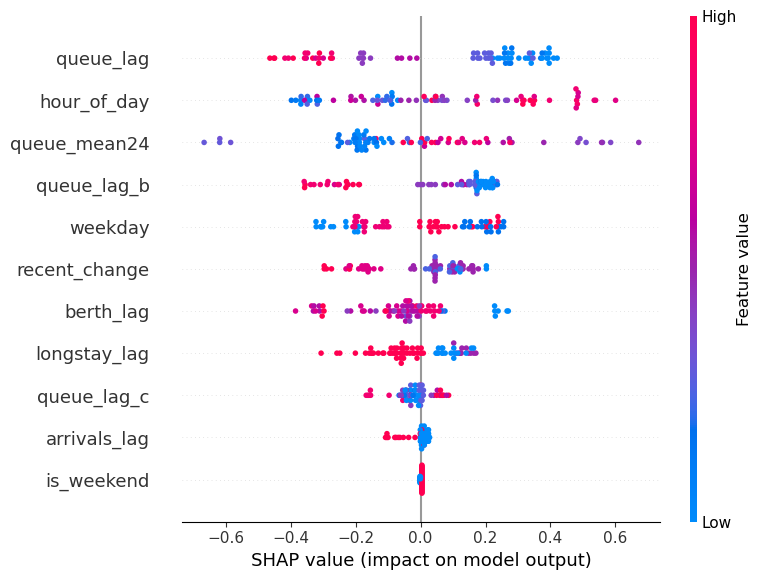

In [22]:
import shap, matplotlib.pyplot as plt

f = build(3); tr, te = split(f, h.queue_ships); cols = list(f.columns)
m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=10,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      random_state=42, verbose=-1).fit(tr[cols], tr.y - tr.queue_lag)
sv = shap.TreeExplainer(m).shap_values(te[cols])
shap.summary_plot(sv, te[cols], show=False)
plt.tight_layout(); plt.savefig("shap_summary.png", dpi=150); plt.show()

In [23]:
import numpy as np, pandas as pd, joblib
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)

lagc = f"queue_lag{H}"
X_tr, X_te = train[feature_cols], test[feature_cols]
y_tr, y_te = train.queue_ships, test.queue_ships

def lgbr(): return lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=7,
                                     min_child_samples=10, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.8, random_state=42, verbose=-1)
def rfr():  return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)

def row(name, pred):
    return [name, round(mean_absolute_error(y_te, pred), 2),
            round(np.sqrt(mean_squared_error(y_te, pred)), 2), round(r2_score(y_te, pred), 2)]

# ---------- Regression: queue size 3 hours ahead ----------
results = [row("Baseline: same as 3h ago", test[lagc]),
           row("Baseline: training average", np.full(len(y_te), y_tr.mean()))]
preds = {}
for name, mk in [("Linear Regression", LinearRegression), ("Random Forest", rfr), ("LightGBM", lgbr)]:
    m = mk().fit(X_tr, y_tr);                       preds[name] = m.predict(X_te)
    results.append(row(name + " (level)", preds[name]))
    mc = mk().fit(X_tr, y_tr - train[lagc]);        preds[name + " change"] = test[lagc] + mc.predict(X_te)
    results.append(row(name + " (change)", preds[name + " change"]))
res = pd.DataFrame(results, columns=["Model", "MAE (ships)", "RMSE", "R2"])
print(res.to_string(index=False))

# ---------- Classification: Low / Medium / High ----------
order = ["Low", "Medium", "High"]
lab_tr, lab_te = lab(train.queue_ships).astype(str), lab(test.queue_ships).astype(str)
base_c = lab(test[lagc]).astype(str)          # baseline: class of the queue 3h ago

clfs = {"LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7,
                                       min_child_samples=10, class_weight="balanced",
                                       random_state=42, verbose=-1),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                class_weight="balanced", random_state=42)}
n_high = int((lab_te == "High").sum())
pred_c = {}
for name, c in clfs.items():
    c.fit(X_tr, lab_tr); pred_c[name] = c.predict(X_te)
    print(f"\n=== {name} classifier ===")
    print(classification_report(lab_te, pred_c[name], labels=order, zero_division=0))
    print(pd.DataFrame(confusion_matrix(lab_te, pred_c[name], labels=order),
                       index=[f"actual {o}" for o in order], columns=[f"pred {o}" for o in order]))
print("\n=== Baseline: class of 'same as 3h ago' ===")
print(classification_report(lab_te, base_c, labels=order, zero_division=0))

print(f"\nHIGH hours caught (out of {n_high}):")
for name in clfs:
    print(f"  {name}: {int(((pred_c[name]=='High') & (lab_te=='High')).sum())}")
print(f"  Baseline: {int(((base_c=='High') & (lab_te=='High')).sum())}")

# ---------- Save files for Person 3 ----------
out = test[["queue_ships", lagc]].copy()
out["pred_randomforest_change"] = preds["Random Forest change"].values
out["pred_lightgbm_change"]     = preds["LightGBM change"].values
out["actual_class"], out["baseline_class"] = lab_te.values, base_c.values
out["pred_class_lightgbm"], out["pred_class_rf"] = pred_c["LightGBM"], pred_c["Random Forest"]
out.to_csv("test_predictions.csv")
res.to_csv("model_results.csv", index=False)
joblib.dump(clfs["LightGBM"], "lgbm_classifier.pkl")
joblib.dump(lgbr().fit(X_tr, y_tr - train[lagc]), "lgbm_regressor_change.pkl")
print("\nSaved: test_predictions.csv, model_results.csv, 2 model files")

                     Model  MAE (ships)  RMSE    R2
  Baseline: same as 3h ago         0.78  1.17  0.78
Baseline: training average         2.46  2.69 -0.17
 Linear Regression (level)         1.18  1.41  0.68
Linear Regression (change)         1.18  1.41  0.68
     Random Forest (level)         1.12  1.41  0.68
    Random Forest (change)         0.91  1.14  0.79
          LightGBM (level)         1.21  1.55  0.61
         LightGBM (change)         1.01  1.29  0.73

=== LightGBM classifier ===
              precision    recall  f1-score   support

         Low       0.79      0.91      0.85        45
      Medium       0.12      0.15      0.13        13
        High       1.00      0.31      0.48        16

    accuracy                           0.65        74
   macro avg       0.64      0.46      0.48        74
weighted avg       0.72      0.65      0.64        74

               pred Low  pred Medium  pred High
actual Low           41            4          0
actual Medium        11   

Hours used: 253 (~10.5 days)

Queue by time of day
  H = 4.2 | p = 0.242 | effect size (epsilon^2) = 0.00
                 hours  median queue  mean queue
Night 00-05         66           6.0        6.64
Morning 06-11       66           5.5        6.15
Afternoon 12-17     61           6.0        5.90
Evening 18-23       60           6.5        6.63

Queue by berth occupancy (same hour, diagnostic only)
  H = 51.2 | p = 7.48e-12 | effect size (epsilon^2) = 0.20
        hours  median queue  mean queue
Low        84           8.0        7.60
Medium     84           6.5        6.33
High       85           5.0        5.08

Queue: weekday vs weekend
  H = 0.2 | p = 0.63 | effect size (epsilon^2) = 0.00
         hours  median queue  mean queue
Weekday    157           6.0        6.44
Weekend     96           6.0        6.16

Spearman correlations:
                  queue_ships  ships_at_berth  arrivals  long_stay_ships  \
queue_ships             1.00           -0.47      0.22             0.01

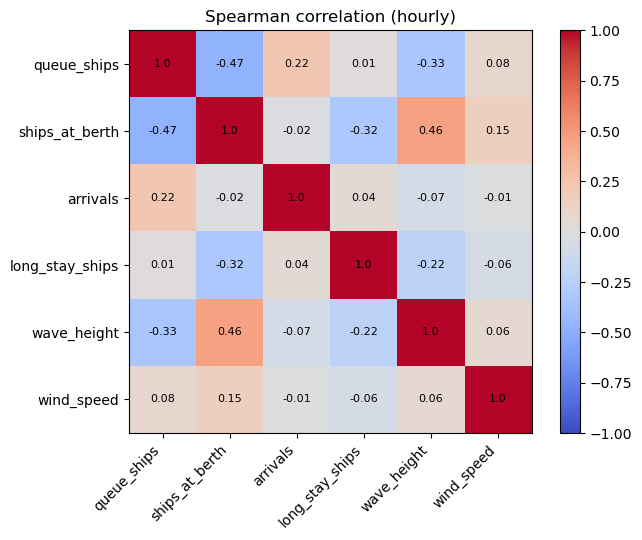


Queue ship-hours in the period: 1,602
Assumed rate / ship / day Queue cost (period)  Per day Avoided if 10% cut Avoided if 20% cut
                  $15,000          $1,001,250  $94,980           $100,125           $200,250
                  $30,000          $2,002,500 $189,960           $200,250           $400,500
                  $45,000          $3,003,750 $284,941           $300,375           $600,750


In [24]:
from scipy.stats import kruskal, spearmanr
import matplotlib.pyplot as plt

d = h[(h.index >= data_start + pd.Timedelta(hours=LONG_H)) & h.queue_ships.notna()].copy()
days = len(d) / 24
print("Hours used:", len(d), f"(~{days:.1f} days)")

# ---------- Kruskal-Wallis ----------
def kw(groups, labels, title):
    stat, p = kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    eps2 = max(0, (stat - k + 1) / (n - k))        # effect size
    print(f"\n{title}\n  H = {stat:.1f} | p = {p:.3g} | effect size (epsilon^2) = {eps2:.2f}")
    print(pd.DataFrame({"hours": [len(g) for g in groups],
                        "median queue": [np.median(g) for g in groups],
                        "mean queue": [round(np.mean(g), 2) for g in groups]}, index=labels))

d["block"] = pd.cut(d.hour_of_day, [-1, 5, 11, 17, 23],
                    labels=["Night 00-05", "Morning 06-11", "Afternoon 12-17", "Evening 18-23"])
d["berth_level"] = pd.qcut(d.ships_at_berth.rank(method="first"), 3, labels=["Low", "Medium", "High"])
d["daytype"] = np.where(d.weekday >= 5, "Weekend", "Weekday")

for col, title in [("block", "Queue by time of day"),
                   ("berth_level", "Queue by berth occupancy (same hour, diagnostic only)"),
                   ("daytype", "Queue: weekday vs weekend")]:
    labels = list(d[col].cat.categories) if hasattr(d[col], "cat") else sorted(d[col].unique())
    kw([d.loc[d[col] == l, "queue_ships"].values for l in labels], labels, title)

# ---------- Spearman correlation heatmap ----------
cols = [c for c in ["queue_ships", "ships_at_berth", "arrivals", "long_stay_ships",
                    "wave_height", "wind_speed"] if c in d.columns]
corr = d[cols].corr(method="spearman").round(2)
print("\nSpearman correlations:\n", corr)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Spearman correlation (hourly)"); plt.tight_layout()
plt.savefig("spearman_heatmap.png", dpi=150); plt.show()

# ---------- Waiting time of usable visits, by vessel group (descriptive) ----------
if "v3" in globals():
    vt = df.groupby("mmsi").vessel_type.first()
    u = v3[(v3.status == "complete") & ~v3.starts_at_edge & ~v3.has_gap].copy()
    u["group"] = np.where(u.mmsi.map(vt) >= 80, "Tanker (80-89)", "Cargo (70-79)")
    print("\nUsable visits by vessel group:")
    print(u.groupby("group").wait_hours.agg(["count", "median", "mean", "max"]).round(1))
    print("Too few visits per group for a statistical test. Descriptive only.")

# ---------- Demurrage scenario (USD, assumed rates) ----------
ship_hours = d.queue_ships.sum()               # ship-hours spent in the queue
RATES = [15_000, 30_000, 45_000]               # ASSUMED USD per ship per day. Replace with a rate you can cite.
rows = []
for r in RATES:
    total = ship_hours / 24 * r
    rows.append([f"${r:,}", f"${total:,.0f}", f"${total / days:,.0f}",
                 f"${total * 0.10:,.0f}", f"${total * 0.20:,.0f}"])
print(f"\nQueue ship-hours in the period: {ship_hours:,.0f}")
print(pd.DataFrame(rows, columns=["Assumed rate / ship / day", "Queue cost (period)",
                                  "Per day", "Avoided if 10% cut", "Avoided if 20% cut"]).to_string(index=False))
if "u" in globals():
    print(f"\nUsable visits only: {u.wait_hours.sum():.0f} waiting hours "
          f"-> at $30,000/day = ${u.wait_hours.sum()/24*30000:,.0f}")

In [26]:
MAX_GAP_H, MIN_DWELL_H, EDGE_H = 6, 1.0, 2
rows = []

for mmsi, g in df.groupby("mmsi"):
    start = last_slow = prev_t = None
    after_berth, max_gap = False, 0.0
    for t, z in zip(g.base_date_time, g.zone):
        if prev_t is not None:
            gap = (t - prev_t).total_seconds() / 3600
            if gap > 24:
                after_berth = False
            if start is not None:
                max_gap = max(max_gap, gap)
        if z == "berth":
            if start is not None and (last_slow - start).total_seconds()/3600 >= MIN_DWELL_H:
                rows.append((mmsi, start, t, (t-start).total_seconds()/3600, "complete", max_gap))
            start = last_slow = None
            max_gap, after_berth = 0.0, True
        elif z == "anchorage" and not after_berth:
            confirmed = start is not None and (last_slow - start).total_seconds()/3600 >= MIN_DWELL_H
            if start is None or (not confirmed and (t - last_slow).total_seconds()/3600 > MIN_DWELL_H):
                start, max_gap = t, 0.0
            last_slow = t
        prev_t = t
    if start is not None and (last_slow - start).total_seconds()/3600 >= MIN_DWELL_H:
        near_end = g.base_date_time.iloc[-1] >= data_end - pd.Timedelta(hours=6)
        rows.append((mmsi, start, pd.NaT, None,
                     "still_waiting_at_end" if near_end else "left_or_lost", max_gap))

v3 = pd.DataFrame(rows, columns=["mmsi","anchorage_arrival","berth_entry","wait_hours","status","max_gap_h"])
v3["starts_at_edge"] = v3.anchorage_arrival < data_start + pd.Timedelta(hours=EDGE_H)
v3["has_gap"] = v3.max_gap_h > MAX_GAP_H
v3["usable"] = (v3.status == "complete") & ~v3.starts_at_edge & ~v3.has_gap

v3.to_csv("visits_final.csv", index=False)
print("Visits found:", len(v3), "| usable:", int(v3.usable.sum()))
print(v3.status.value_counts())

Visits found: 44 | usable: 12
status
complete                21
left_or_lost            16
still_waiting_at_end     7
Name: count, dtype: int64


In [27]:
dd = d[["queue_ships","ships_at_berth","arrivals","wave_height"]].dropna()
t = np.arange(len(dd))
detrend = lambda x: x - np.polyval(np.polyfit(t, x, 1), t)
for col in ["ships_at_berth", "arrivals", "wave_height"]:
    rho, _ = spearmanr(detrend(dd[col].values), detrend(dd.queue_ships.values))
    print(f"After removing time trend: {col} vs queue: rho = {rho:.2f}")

After removing time trend: ships_at_berth vs queue: rho = -0.53
After removing time trend: arrivals vs queue: rho = 0.08
After removing time trend: wave_height vs queue: rho = -0.30


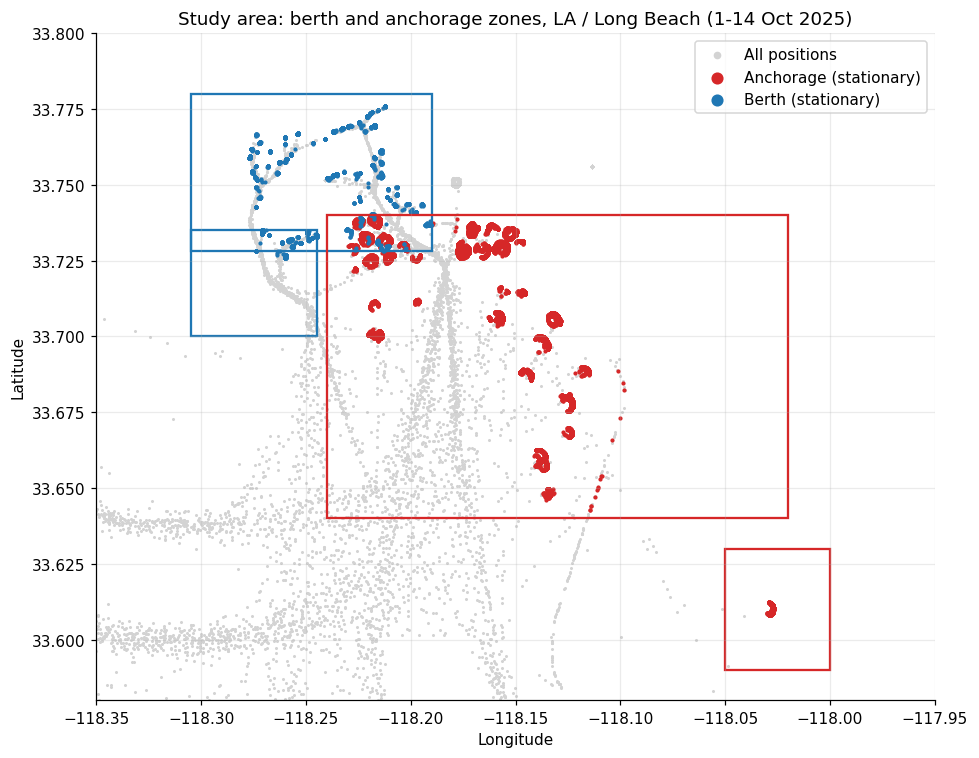

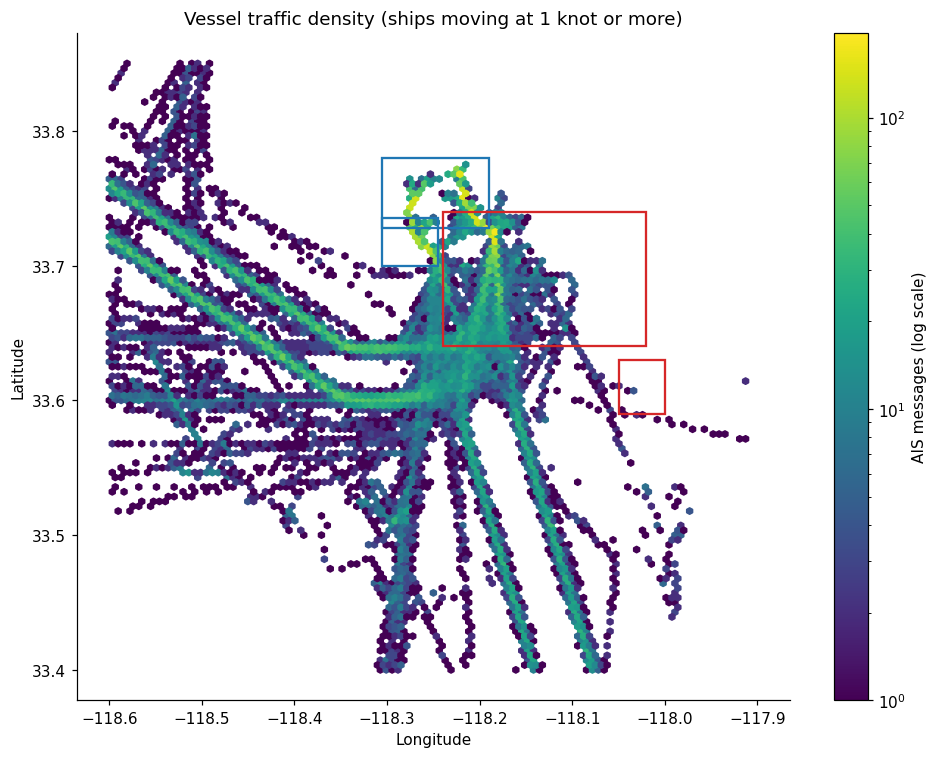

Anchorage clusters found: 16 | noise positions: 22
         positions  ships      lat       lon
cluster                                     
0              312      1  33.6877 -118.1445
1             2807     29  33.7319 -118.2161
2             2628     23  33.7314 -118.1651
3              171      2  33.6483 -118.1341
4              905      5  33.7023 -118.1335
5              347      5  33.7062 -118.1580
6              537      3  33.6589 -118.1374
7              307      5  33.7005 -118.2163
8               98      1  33.7116 -118.1970
9              140      4  33.7147 -118.1501
10              33      1  33.6485 -118.1118
11              52      1  33.7106 -118.2175
12             177      2  33.6888 -118.1166
13             404      1  33.6099 -118.0280
14             606      1  33.6783 -118.1241
15             171      1  33.6685 -118.1240


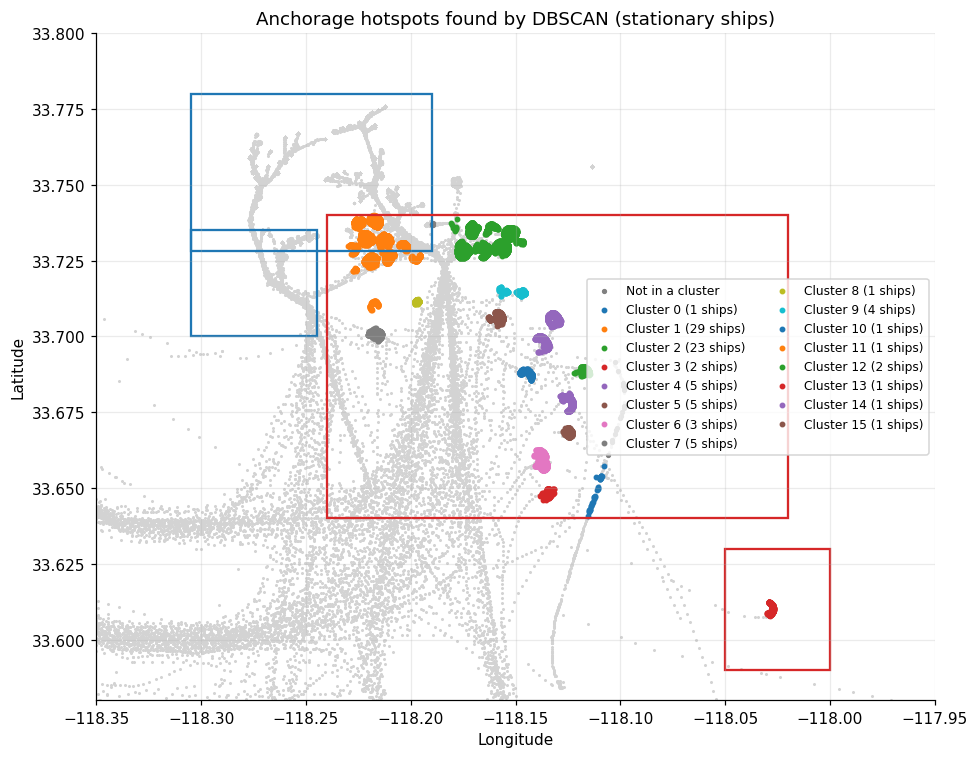

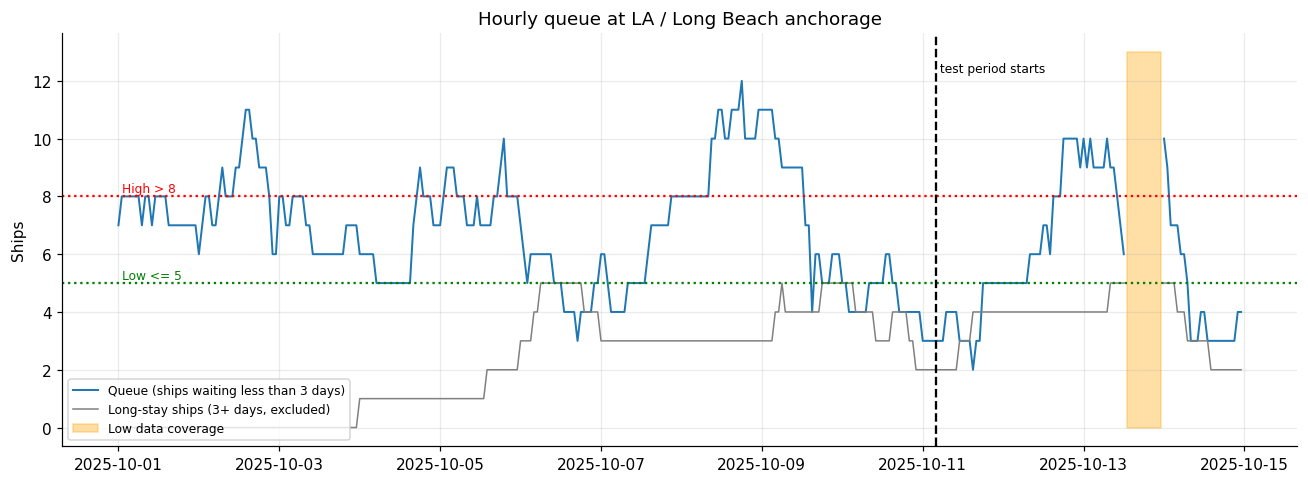

In [28]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN

os.makedirs("charts", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"charts/{name}.png", dpi=200); plt.show()

# ---- load the saved files (works even after a kernel restart) ----
df = pd.read_parquet("ais_with_zones.parquet",
                     columns=["mmsi","base_date_time","latitude","longitude","sog","vessel_type","zone"])
h  = pd.read_csv("hourly_table_full.csv", index_col=0, parse_dates=True)
v  = pd.read_csv("visits_final.csv", parse_dates=["anchorage_arrival", "berth_entry"])
tp = pd.read_csv("test_predictions.csv", index_col=0, parse_dates=True)
mr = pd.read_csv("model_results.csv")
if "wave_height" not in h.columns:
    w = pd.read_csv("Data/weather.csv", parse_dates=["time"]).set_index("time")
    h = h.join(w, how="left")

BERTH, BERTH_W = (-118.305, -118.190, 33.728, 33.780), (-118.305, -118.245, 33.700, 33.735)
ANCH_IN, ANCH_OUT = (-118.240, -118.020, 33.640, 33.740), (-118.050, -118.000, 33.590, 33.630)
Q1, Q2 = 5, 8                      # Low / Medium / High thresholds (from training data)
test_start = tp.index.min()
valid = h[(h.index >= h.index.min() + pd.Timedelta(hours=72)) & h.queue_ships.notna()].copy()

def boxes(ax):
    for b, c in [(BERTH, "tab:blue"), (BERTH_W, "tab:blue"), (ANCH_IN, "tab:red"), (ANCH_OUT, "tab:red")]:
        ax.add_patch(Rectangle((b[0], b[2]), b[1]-b[0], b[3]-b[2], fill=False, edgecolor=c, lw=1.5))

# ---------- Chart 1: study area and zones ----------
fig, ax = plt.subplots(figsize=(9, 7))
s = df.sample(min(len(df), 60000), random_state=1)
ax.scatter(s.longitude, s.latitude, s=1, c="lightgray", label="All positions")
for z, c in [("anchorage", "tab:red"), ("berth", "tab:blue")]:
    p = df[df.zone == z].sample(min((df.zone == z).sum(), 20000), random_state=1)
    ax.scatter(p.longitude, p.latitude, s=3, c=c, label=f"{z.capitalize()} (stationary)")
boxes(ax)
ax.set_xlim(-118.35, -117.95); ax.set_ylim(33.58, 33.80)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Study area: berth and anchorage zones, LA / Long Beach (1-14 Oct 2025)")
ax.legend(markerscale=4); save(fig, "01_zone_map")

# ---------- Chart 2: traffic density (moving ships only) ----------
mv = df[df.sog >= 1]
fig, ax = plt.subplots(figsize=(9, 7))
hb = ax.hexbin(mv.longitude, mv.latitude, gridsize=110, bins="log", cmap="viridis", mincnt=1,
               extent=(-118.6, -117.9, 33.4, 33.85))
boxes(ax); fig.colorbar(hb, label="AIS messages (log scale)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(False)
ax.set_title("Vessel traffic density (ships moving at 1 knot or more)")
save(fig, "02_traffic_density")

# ---------- Chart 3: anchorage hotspots (DBSCAN) ----------
an = df[df.zone == "anchorage"].copy()
an["lat_r"], an["lon_r"] = an.latitude.round(4), an.longitude.round(4)
pts = an.drop_duplicates(["mmsi", "lat_r", "lon_r"]).copy()      # one point per ship per spot
x = pts.longitude * np.cos(np.radians(33.7)) * 111.32            # degrees -> km
y = pts.latitude * 110.57
EPS_KM, MIN_PTS = 0.5, 10                                        # fixed settings
pts["cluster"] = DBSCAN(eps=EPS_KM, min_samples=MIN_PTS).fit_predict(np.c_[x, y])
summ = (pts[pts.cluster >= 0].groupby("cluster")
        .agg(positions=("mmsi", "size"), ships=("mmsi", "nunique"),
             lat=("latitude", "mean"), lon=("longitude", "mean")).round(4))
print("Anchorage clusters found:", len(summ), "| noise positions:", int((pts.cluster < 0).sum()))
print(summ)

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df.longitude, df.latitude, s=1, c="lightgray")
noise = pts[pts.cluster < 0]
ax.scatter(noise.longitude, noise.latitude, s=6, c="gray", label="Not in a cluster")
for c in sorted(pts.cluster[pts.cluster >= 0].unique()):
    p = pts[pts.cluster == c]
    ax.scatter(p.longitude, p.latitude, s=8, label=f"Cluster {c} ({p.mmsi.nunique()} ships)")
boxes(ax); ax.set_xlim(-118.35, -117.95); ax.set_ylim(33.58, 33.80)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Anchorage hotspots found by DBSCAN (stationary ships)")
ax.legend(fontsize=8, ncol=2); save(fig, "03_anchorage_dbscan")

# ---------- Chart 4: queue over time ----------
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(h.index, h.queue_ships, lw=1.3, label="Queue (ships waiting less than 3 days)")
ax.plot(h.index, h.long_stay_ships, lw=1, color="gray", label="Long-stay ships (3+ days, excluded)")
ax.fill_between(h.index, 0, h.queue_ships.max() + 1, where=h.low_coverage.astype(bool), color="orange",
                alpha=0.35, label="Low data coverage")
ax.axhline(Q1, ls=":", c="green"); ax.axhline(Q2, ls=":", c="red")
ax.text(h.index[1], Q1 + .15, f"Low <= {Q1}", color="green", fontsize=8)
ax.text(h.index[1], Q2 + .15, f"High > {Q2}", color="red", fontsize=8)
ax.axvline(test_start, c="k", ls="--"); ax.text(test_start, h.queue_ships.max() + .3, " test period starts", fontsize=8)
ax.set_ylabel("Ships"); ax.set_title("Hourly queue at LA / Long Beach anchorage")
ax.legend(loc="lower left", fontsize=8); save(fig, "04_queue_over_time")

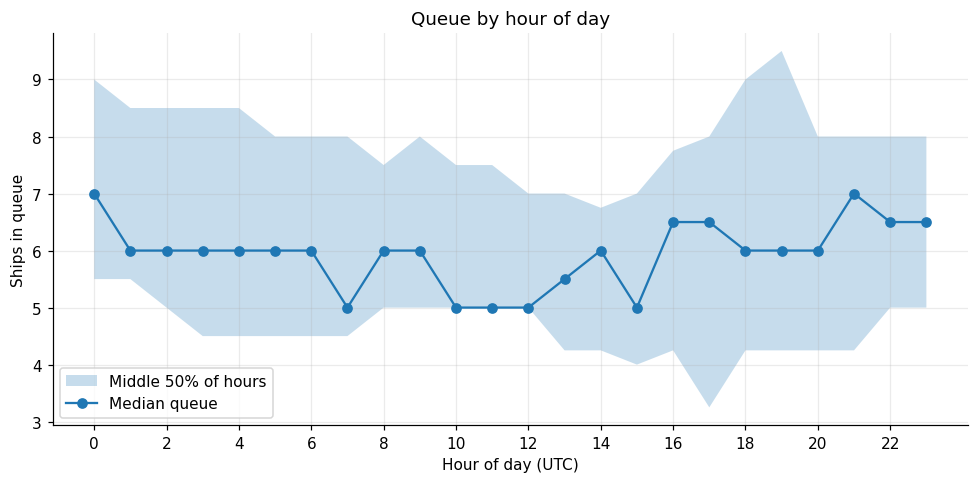

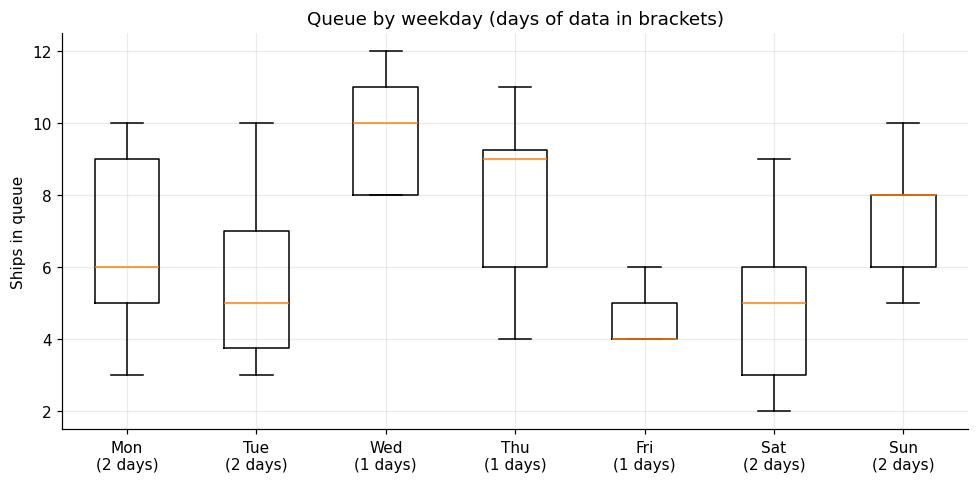

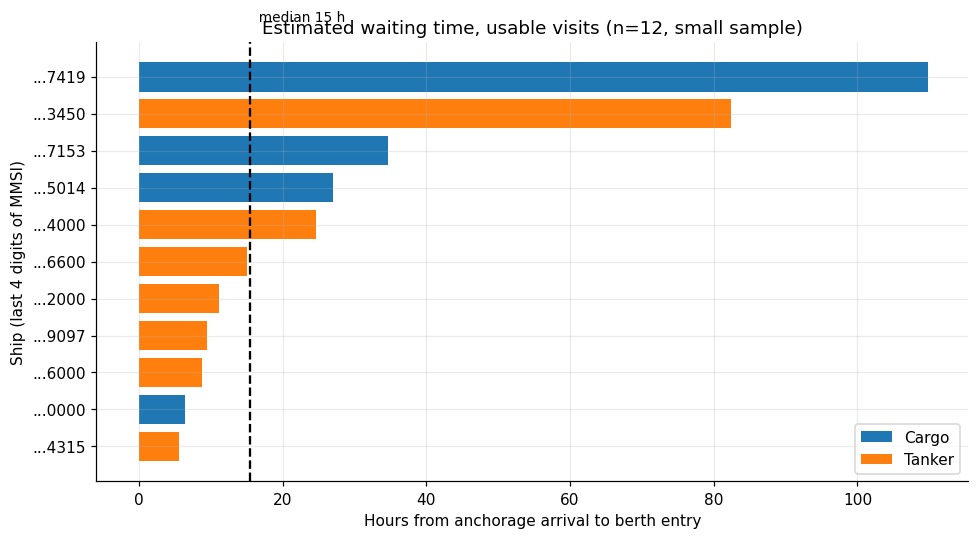

        count  median    max
group                       
Cargo       5    27.0  109.9
Tanker      7    11.1   82.4


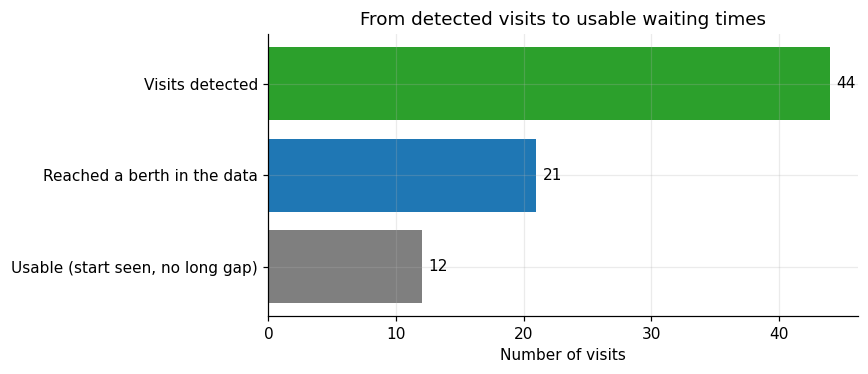

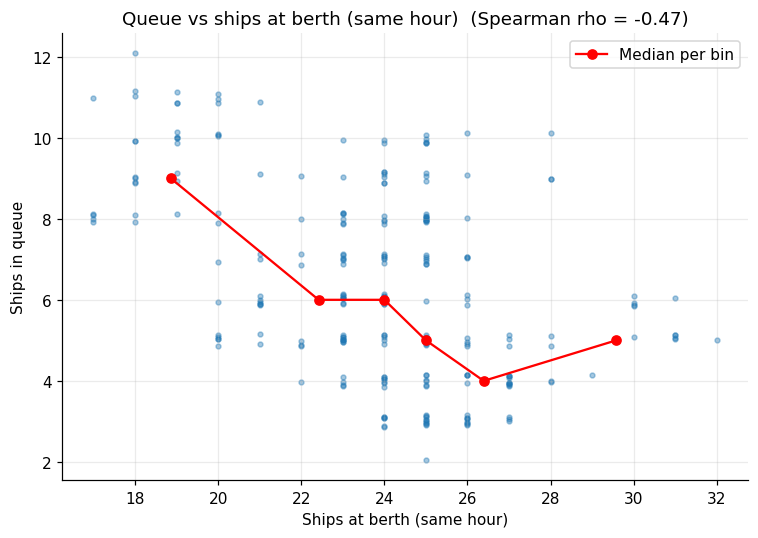

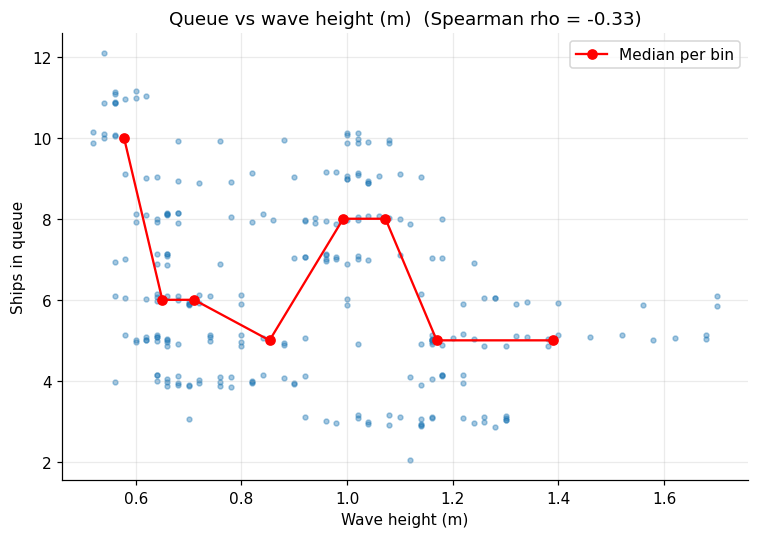

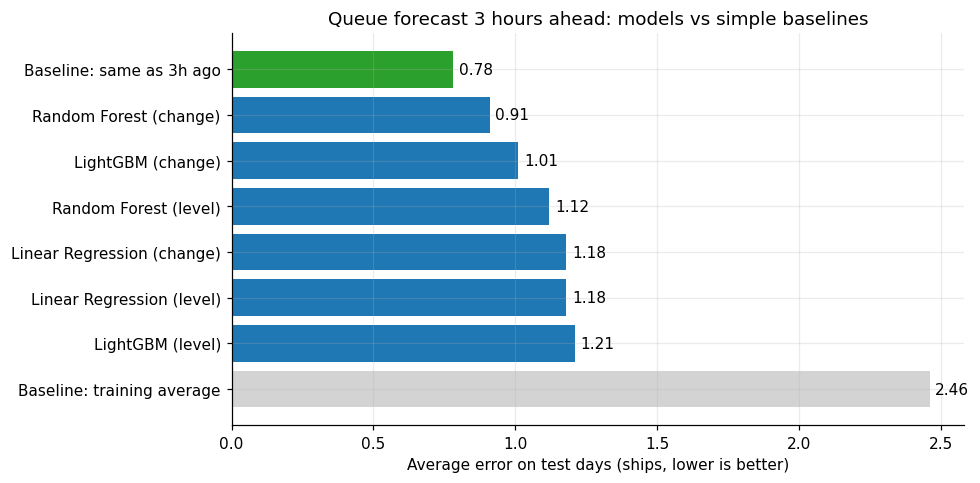

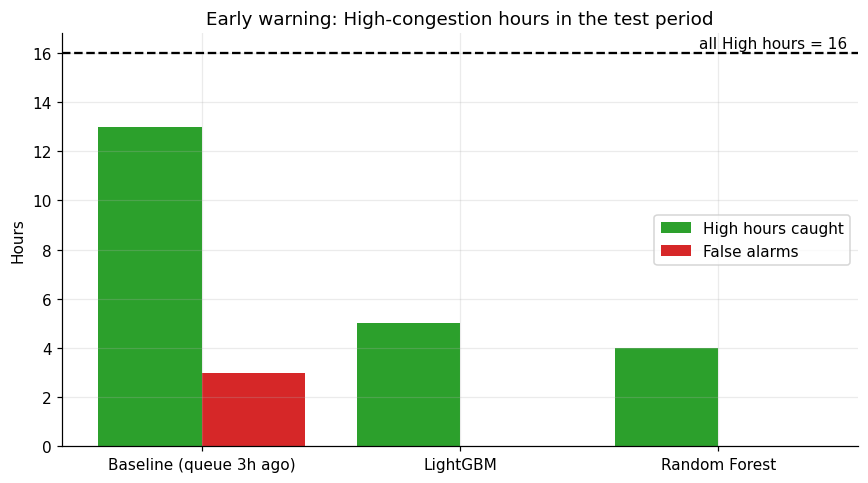

                    Method  High hours caught  False alarms
0  Baseline (queue 3h ago)                 13             3
1                 LightGBM                  5             0
2            Random Forest                  4             0


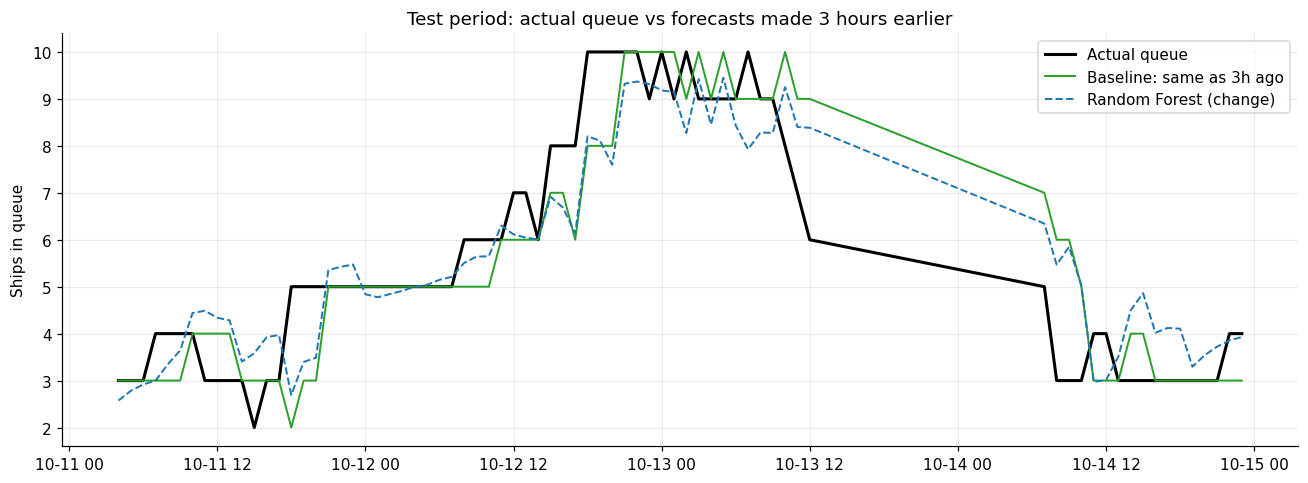

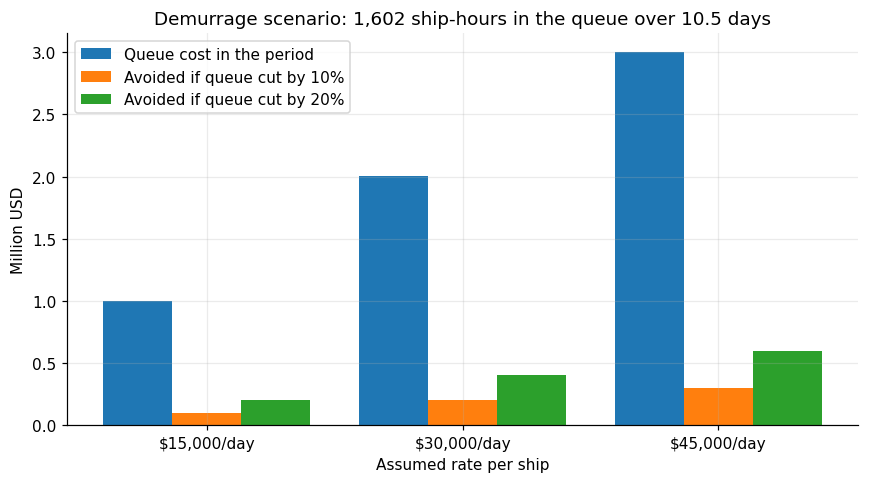


Saved charts: ['01_zone_map.png', '02_traffic_density.png', '03_anchorage_dbscan.png', '04_queue_over_time.png', '05_queue_by_hour.png', '06_queue_by_weekday.png', '07_waiting_time_visits.png', '08_visit_funnel.png', '09_queue_vs_berth.png', '10_queue_vs_wave.png', '11_model_comparison.png', '12_high_hours_caught.png', '13_actual_vs_predicted.png', '14_demurrage_scenarios.png']


In [29]:
# ---------- Chart 5: queue by hour of day ----------
g = valid.groupby("hour_of_day").queue_ships
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(g.median().index, g.quantile(.25), g.quantile(.75), alpha=.25, label="Middle 50% of hours")
ax.plot(g.median().index, g.median(), marker="o", label="Median queue")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day (UTC)"); ax.set_ylabel("Ships in queue")
ax.set_title("Queue by hour of day"); ax.legend(); save(fig, "05_queue_by_hour")

# ---------- Chart 6: queue by weekday ----------
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(9, 4.5))
data = [valid.loc[valid.weekday == i, "queue_ships"] for i in range(7)]
ax.boxplot(data)
ax.set_xticklabels([f"{n}\n({valid[valid.weekday == i].index.normalize().nunique()} days)" for i, n in enumerate(names)])
ax.set_ylabel("Ships in queue"); ax.set_title("Queue by weekday (days of data in brackets)")
save(fig, "06_queue_by_weekday")

# ---------- Chart 7: waiting time of usable visits ----------
u = v[v.usable].copy()
vt = df.groupby("mmsi").vessel_type.first()
u["group"] = np.where(u.mmsi.map(vt) >= 80, "Tanker", "Cargo")
u = u.sort_values("wait_hours")
fig, ax = plt.subplots(figsize=(9, 5))
cols = u.group.map({"Cargo": "tab:blue", "Tanker": "tab:orange"})
ax.barh([f"...{str(m)[-4:]}" for m in u.mmsi], u.wait_hours, color=cols)
ax.axvline(u.wait_hours.median(), c="k", ls="--")
ax.text(u.wait_hours.median(), len(u) - 0.5, f"  median {u.wait_hours.median():.0f} h", fontsize=9)
ax.set_xlabel("Hours from anchorage arrival to berth entry"); ax.set_ylabel("Ship (last 4 digits of MMSI)")
ax.set_title(f"Estimated waiting time, usable visits (n={len(u)}, small sample)")
for k, c in [("Cargo", "tab:blue"), ("Tanker", "tab:orange")]: ax.bar(0, 0, color=c, label=k)
ax.legend(); save(fig, "07_waiting_time_visits")
print(u.groupby("group").wait_hours.agg(["count", "median", "max"]).round(1))

# ---------- Chart 8: visit funnel ----------
f = [("Visits detected", len(v)), ("Reached a berth in the data", int((v.status == "complete").sum())),
     ("Usable (start seen, no long gap)", int(v.usable.sum()))]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh([a for a, _ in f][::-1], [b for _, b in f][::-1], color=["tab:gray", "tab:blue", "tab:green"])
for i, (_, b) in enumerate(f[::-1]): ax.text(b + .5, i, str(b), va="center")
ax.set_xlabel("Number of visits"); ax.set_title("From detected visits to usable waiting times")
save(fig, "08_visit_funnel")

# ---------- Charts 9 and 10: associations ----------
def assoc(col, label, name, bins=8):
    d = valid[[col, "queue_ships"]].dropna()
    rho, _ = spearmanr(d[col], d.queue_ships)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(d[col], d.queue_ships + np.random.default_rng(0).uniform(-.15, .15, len(d)), s=10, alpha=.4)
    b = pd.qcut(d[col], bins, duplicates="drop")
    m = d.groupby(b, observed=True).agg(x=(col, "mean"), y=("queue_ships", "median"))
    ax.plot(m.x, m.y, "r-o", label="Median per bin")
    ax.set_xlabel(label); ax.set_ylabel("Ships in queue")
    ax.set_title(f"Queue vs {label.lower()}  (Spearman rho = {rho:.2f})"); ax.legend()
    save(fig, name)
assoc("ships_at_berth", "Ships at berth (same hour)", "09_queue_vs_berth")
if "wave_height" in valid.columns:
    assoc("wave_height", "Wave height (m)", "10_queue_vs_wave")

# ---------- Chart 11: model comparison ----------
m = mr.sort_values("MAE (ships)", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["tab:green" if "same as 3h" in n else "lightgray" if "average" in n else "tab:blue" for n in m.Model]
ax.barh(m.Model, m["MAE (ships)"], color=colors)
for i, val in enumerate(m["MAE (ships)"]): ax.text(val + .02, i, f"{val:.2f}", va="center")
ax.set_xlabel("Average error on test days (ships, lower is better)")
ax.set_title("Queue forecast 3 hours ahead: models vs simple baselines"); save(fig, "11_model_comparison")

# ---------- Chart 12: High-congestion hours caught ----------
is_high = tp.actual_class == "High"
rows = []
for name, col in [("Baseline (queue 3h ago)", "baseline_class"), ("LightGBM", "pred_class_lightgbm"),
                  ("Random Forest", "pred_class_rf")]:
    rows.append((name, int(((tp[col] == "High") & is_high).sum()), int(((tp[col] == "High") & ~is_high).sum())))
r = pd.DataFrame(rows, columns=["Method", "High hours caught", "False alarms"])
fig, ax = plt.subplots(figsize=(8, 4.5)); xx = np.arange(len(r))
ax.bar(xx - .2, r["High hours caught"], .4, label="High hours caught", color="tab:green")
ax.bar(xx + .2, r["False alarms"], .4, label="False alarms", color="tab:red")
ax.set_xticks(xx); ax.set_xticklabels(r.Method)
ax.axhline(is_high.sum(), c="k", ls="--"); ax.text(len(r) - .5, is_high.sum() + .2, f"all High hours = {int(is_high.sum())}", ha="right")
ax.set_ylabel("Hours"); ax.set_title("Early warning: High-congestion hours in the test period"); ax.legend()
save(fig, "12_high_hours_caught")
print(r)

# ---------- Chart 13: actual vs predicted ----------
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(tp.index, tp.queue_ships, "k", lw=2, label="Actual queue")
ax.plot(tp.index, tp.queue_lag3, c="tab:green", lw=1.3, label="Baseline: same as 3h ago")
ax.plot(tp.index, tp.pred_randomforest_change, c="tab:blue", lw=1.3, ls="--", label="Random Forest (change)")
ax.set_ylabel("Ships in queue"); ax.set_title("Test period: actual queue vs forecasts made 3 hours earlier")
ax.legend(); save(fig, "13_actual_vs_predicted")

# ---------- Chart 14: demurrage scenarios ----------
ship_hours = valid.queue_ships.sum(); days = len(valid) / 24
rates = [15000, 30000, 45000]                 # ASSUMED USD per ship per day
tot = np.array([ship_hours / 24 * r for r in rates]) / 1e6
fig, ax = plt.subplots(figsize=(8, 4.5)); xx = np.arange(3)
ax.bar(xx - .27, tot, .27, label="Queue cost in the period")
ax.bar(xx, tot * .10, .27, label="Avoided if queue cut by 10%")
ax.bar(xx + .27, tot * .20, .27, label="Avoided if queue cut by 20%")
ax.set_xticks(xx); ax.set_xticklabels([f"${r:,}/day" for r in rates])
ax.set_ylabel("Million USD"); ax.set_xlabel("Assumed rate per ship")
ax.set_title(f"Demurrage scenario: {ship_hours:,.0f} ship-hours in the queue over {days:.1f} days")
ax.legend(); save(fig, "14_demurrage_scenarios")
print("\nSaved charts:", sorted(os.listdir("charts")))